# CLIP Sport & Outdoor — Notebook complet (V1, V2, V3, ablation, visualisations, image→image)

**Avant de lancer "Run All" :**
1. Ajoute le dataset Flickr30k via "Add Input" (recherche `flickr30k`, source `adityajn105`)
2. Active le GPU : Settings → Accelerator → GPU T4
3. Vérifie les chemins `RAW_IMAGES_DIR` / `RAW_CAPTIONS_CSV` dans la cellule Config si tu utilises une autre source de dataset

Ce notebook sauvegarde des checkpoints zip de sécurité après chaque grande étape, dans `/kaggle/working/`.
Durée totale estimée : **4h30 - 6h** (GPU T4).


## 0. Installation

In [1]:
!pip install faiss-cpu scikit-learn --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 61.6 MB/s eta 0:00:00


## 1. Configuration

In [2]:
%%writefile config.py
import os

DOMAIN_NAME = "sport_outdoor"

SPORT_KEYWORDS = [
    "run", "running", "runs", "ran",
    "jump", "jumping", "jumps", "jumped",
    "play", "playing", "plays", "played",
    "soccer", "football", "basketball", "baseball", "tennis",
    "bike", "biking", "bicycle", "cyclist", "cycling",
    "swim", "swimming", "swimmer",
    "ski", "skiing", "skier", "snowboard",
    "climb", "climbing", "climber",
    "surf", "surfing", "surfer",
    "skateboard", "skateboarding",
    "race", "racing", "marathon",
    "gym", "exercise", "exercising", "workout",
    "hike", "hiking", "trail",
    "field", "stadium", "court", "track",
]

SEED = 42

SUBSET_SIZE = 12682   # toutes les images sport/outdoor disponibles
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.1

BASE_DIR = "/kaggle/working"

# !!! A AJUSTER si ton dataset Kaggle a un chemin different !!!
RAW_IMAGES_DIR = "/kaggle/input/datasets/adityajn105/flickr30k/Images"
RAW_CAPTIONS_CSV = "/kaggle/input/datasets/adityajn105/flickr30k/captions.txt"

OUTPUT_DIR = os.path.join(BASE_DIR, "sport_subset")
SUBSET_CAPTIONS_CSV = os.path.join(OUTPUT_DIR, "captions_sport.csv")
SPLITS_DIR = os.path.join(OUTPUT_DIR, "splits")

EMBEDDINGS_DIR = os.path.join(BASE_DIR, "embeddings")
BASELINE_INDEX_PATH = os.path.join(EMBEDDINGS_DIR, "baseline_zeroshot.index")
BASELINE_MAPPING_PATH = os.path.join(EMBEDDINGS_DIR, "baseline_id_to_path.json")

FINETUNED_INDEX_PATH = os.path.join(EMBEDDINGS_DIR, "finetuned.index")
FINETUNED_MAPPING_PATH = os.path.join(EMBEDDINGS_DIR, "finetuned_id_to_path.json")

FINETUNED_V3_INDEX_PATH = os.path.join(EMBEDDINGS_DIR, "finetuned_v3.index")
FINETUNED_V3_MAPPING_PATH = os.path.join(EMBEDDINGS_DIR, "finetuned_v3_id_to_path.json")

ADAPTER_CHECKPOINT_PATH = os.path.join(BASE_DIR, "adapter_checkpoint.pt")
ADAPTER_BEST_PATH = os.path.join(BASE_DIR, "adapter_best.pt")

ADAPTER_V2_CHECKPOINT_PATH = os.path.join(BASE_DIR, "adapter_v2_checkpoint.pt")
ADAPTER_V2_BEST_PATH = os.path.join(BASE_DIR, "adapter_v2_best.pt")

ADAPTER_V3_CHECKPOINT_PATH = os.path.join(BASE_DIR, "adapter_v3_checkpoint.pt")
ADAPTER_V3_BEST_PATH = os.path.join(BASE_DIR, "adapter_v3_best.pt")

CLIP_MODEL_NAME = "openai/clip-vit-base-patch32"
EMBEDDING_DIM = 512

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SPLITS_DIR, exist_ok=True)
os.makedirs(EMBEDDINGS_DIR, exist_ok=True)


Writing config.py


## 2. Filtrage du dataset (domaine Sport & Outdoor)

In [3]:
%%writefile filter_dataset.py
import os
import re
import json
import random
import pandas as pd

from config import (
    RAW_CAPTIONS_CSV, RAW_IMAGES_DIR, SPORT_KEYWORDS, SUBSET_SIZE,
    TRAIN_SPLIT, VAL_SPLIT, SUBSET_CAPTIONS_CSV, SPLITS_DIR, SEED,
)


def load_raw_captions(path: str = RAW_CAPTIONS_CSV) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={"image": "image_id"})
    df["image_id"] = df["image_id"].astype(str).str.strip()
    df["caption"] = df["caption"].astype(str).str.strip()
    return df[["image_id", "caption"]]


def matches_sport_keywords(caption: str, keywords) -> bool:
    caption_lower = caption.lower()
    for kw in keywords:
        if re.search(rf"\b{re.escape(kw)}\b", caption_lower):
            return True
    return False


def filter_dataset():
    random.seed(SEED)
    print("Chargement des captions brutes...")
    df = load_raw_captions()
    print(f"Total captions brutes: {len(df)}")

    df["image_path"] = df["image_id"].apply(lambda x: os.path.join(RAW_IMAGES_DIR, x))
    df = df[df["image_path"].apply(os.path.exists)]
    print(f"Captions avec image existante: {len(df)}")

    mask = df["caption"].apply(lambda c: matches_sport_keywords(c, SPORT_KEYWORDS))
    sport_df = df[mask].reset_index(drop=True)
    print(f"Captions matchant le domaine sport/outdoor: {len(sport_df)}")

    unique_images = sport_df["image_id"].unique().tolist()
    print(f"Images uniques dans le domaine: {len(unique_images)}")

    if len(unique_images) < SUBSET_SIZE:
        print(f"ATTENTION: seulement {len(unique_images)} images trouvees, on prend toutes.")
        selected_images = unique_images
    else:
        random.shuffle(unique_images)
        selected_images = unique_images[:SUBSET_SIZE]

    selected_set = set(selected_images)
    final_df = sport_df[sport_df["image_id"].isin(selected_set)].reset_index(drop=True)

    final_df[["image_id", "caption"]].to_csv(SUBSET_CAPTIONS_CSV, index=False)
    print(f"Sous-ensemble sauvegarde: {len(final_df)} pairs -> {SUBSET_CAPTIONS_CSV}")

    random.shuffle(selected_images)
    n = len(selected_images)
    n_train = int(n * TRAIN_SPLIT)
    n_val = int(n * VAL_SPLIT)

    train_images = selected_images[:n_train]
    val_images = selected_images[n_train:n_train + n_val]
    test_images = selected_images[n_train + n_val:]

    splits = {"train": train_images, "val": val_images, "test": test_images}
    for split_name, images in splits.items():
        path = os.path.join(SPLITS_DIR, f"{split_name}.json")
        with open(path, "w", encoding="utf-8") as f:
            json.dump(images, f)
        print(f"  {split_name}: {len(images)} images -> {path}")

    return final_df, splits


if __name__ == "__main__":
    filter_dataset()


Writing filter_dataset.py


In [4]:
from filter_dataset import filter_dataset
final_df, splits = filter_dataset()
final_df.head()


Chargement des captions brutes...
Total captions brutes: 158915
Captions avec image existante: 158915
Captions matchant le domaine sport/outdoor: 38933
Images uniques dans le domaine: 12682
Sous-ensemble sauvegarde: 38933 pairs -> /kaggle/working/sport_subset/captions_sport.csv
  train: 10145 images -> /kaggle/working/sport_subset/splits/train.json
  val: 1268 images -> /kaggle/working/sport_subset/splits/val.json
  test: 1269 images -> /kaggle/working/sport_subset/splits/test.json


,image_id,caption,image_path
0,1000268201.jpg,A child in a pink dress is climbing up a set o...,/kaggle/input/datasets/adityajn105/flickr30k/I...
1,1000268201.jpg,A little girl climbing the stairs to her playh...,/kaggle/input/datasets/adityajn105/flickr30k/I...
2,1000268201.jpg,A little girl climbing into a wooden playhouse,/kaggle/input/datasets/adityajn105/flickr30k/I...
3,1000523639.jpg,Two people in the photo are playing the guitar...,/kaggle/input/datasets/adityajn105/flickr30k/I...
4,1000523639.jpg,the two boys playing guitar,/kaggle/input/datasets/adityajn105/flickr30k/I...


## 3. Modules de base (dataset loader, CLIP wrapper, FAISS, recall)

In [5]:
%%writefile dataset_loader.py
import os
import json
import pandas as pd

from config import SUBSET_CAPTIONS_CSV, RAW_IMAGES_DIR, SPLITS_DIR


def load_subset_captions() -> pd.DataFrame:
    df = pd.read_csv(SUBSET_CAPTIONS_CSV)
    df["image_path"] = df["image_id"].apply(lambda x: os.path.join(RAW_IMAGES_DIR, x))
    return df


def load_split(split_name: str) -> list:
    path = os.path.join(SPLITS_DIR, f"{split_name}.json")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def get_split_dataframe(split_name: str) -> pd.DataFrame:
    df = load_subset_captions()
    image_ids = set(load_split(split_name))
    return df[df["image_id"].isin(image_ids)].reset_index(drop=True)


def get_unique_images(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates(subset="image_id").reset_index(drop=True)


Writing dataset_loader.py


In [6]:
%%writefile clip_wrapper.py
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

from config import CLIP_MODEL_NAME


def _extract_tensor(output):
    if isinstance(output, torch.Tensor):
        return output
    if hasattr(output, "pooler_output"):
        return output.pooler_output
    if hasattr(output, "last_hidden_state"):
        return output.last_hidden_state[:, 0, :]
    return output[0]


class CLIPWrapper:
    def __init__(self, model_name: str = CLIP_MODEL_NAME, device: str = None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model = CLIPModel.from_pretrained(model_name).to(self.device)
        self.processor = CLIPProcessor.from_pretrained(model_name)
        print(f"CLIP charge sur {self.device}")

    def freeze_all(self):
        for p in self.model.parameters():
            p.requires_grad = False
        self.model.eval()

    def unfreeze_last_vision_blocks(self, num_blocks: int = 2):
        vision_layers = self.model.vision_model.encoder.layers
        total_layers = len(vision_layers)
        print(f"Encodeur visuel: {total_layers} blocs au total, degel des {num_blocks} derniers")

        for i, layer in enumerate(vision_layers):
            if i >= total_layers - num_blocks:
                for p in layer.parameters():
                    p.requires_grad = True

        for p in self.model.visual_projection.parameters():
            p.requires_grad = True
        if hasattr(self.model.vision_model, "post_layernorm"):
            for p in self.model.vision_model.post_layernorm.parameters():
                p.requires_grad = True

        trainable = sum(p.numel() for p in self.model.parameters() if p.requires_grad)
        total = sum(p.numel() for p in self.model.parameters())
        print(f"Parametres CLIP entrainables: {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")

    def encode_images(self, images, batch_size: int = 32, grad: bool = False) -> torch.Tensor:
        all_feats = []
        ctx = torch.enable_grad() if grad else torch.no_grad()
        with ctx:
            for i in range(0, len(images), batch_size):
                batch = images[i:i + batch_size]
                inputs = self.processor(images=batch, return_tensors="pt").to(self.device)
                feats = self.model.get_image_features(**inputs)
                feats = _extract_tensor(feats)
                feats = feats / feats.norm(p=2, dim=-1, keepdim=True)
                all_feats.append(feats if grad else feats.cpu())
        return torch.cat(all_feats, dim=0)

    def encode_text(self, texts, batch_size: int = 64, grad: bool = False) -> torch.Tensor:
        all_feats = []
        ctx = torch.enable_grad() if grad else torch.no_grad()
        with ctx:
            for i in range(0, len(texts), batch_size):
                batch = texts[i:i + batch_size]
                inputs = self.processor(
                    text=batch, return_tensors="pt", padding=True, truncation=True
                ).to(self.device)
                feats = self.model.get_text_features(**inputs)
                feats = _extract_tensor(feats)
                feats = feats / feats.norm(p=2, dim=-1, keepdim=True)
                all_feats.append(feats if grad else feats.cpu())
        return torch.cat(all_feats, dim=0)


Writing clip_wrapper.py


In [7]:
%%writefile faiss_index.py
import json
import faiss
import numpy as np


class FaissIndex:
    def __init__(self, dim: int):
        self.dim = dim
        self.index = faiss.IndexFlatIP(dim)
        self.id_to_path = {}

    def add(self, embeddings: np.ndarray, image_paths: list):
        assert embeddings.shape[0] == len(image_paths)
        start_id = self.index.ntotal
        self.index.add(embeddings.astype(np.float32))
        for i, path in enumerate(image_paths):
            self.id_to_path[start_id + i] = path

    def search(self, query_embedding: np.ndarray, top_k: int = 5):
        scores, indices = self.index.search(query_embedding.astype(np.float32), top_k)
        results = []
        for score, idx in zip(scores[0], indices[0]):
            if idx == -1:
                continue
            results.append((self.id_to_path[int(idx)], float(score)))
        return results

    def save(self, index_path: str, mapping_path: str):
        faiss.write_index(self.index, index_path)
        with open(mapping_path, "w", encoding="utf-8") as f:
            json.dump(self.id_to_path, f)

    def load(self, index_path: str, mapping_path: str):
        self.index = faiss.read_index(index_path)
        with open(mapping_path, "r", encoding="utf-8") as f:
            raw = json.load(f)
        self.id_to_path = {int(k): v for k, v in raw.items()}
        return self


Writing faiss_index.py


In [8]:
%%writefile recall.py
import os
import numpy as np
import torch
from tqdm import tqdm

from faiss_index import FaissIndex


def recall_at_k(test_df, faiss_index, encode_text_fn, k_values=[1, 5, 10]):
    max_k = max(k_values)
    hits = {k: 0 for k in k_values}

    for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="Recall@K eval"):
        caption = row["caption"]
        gt_image_id = row["image_id"]

        embedding = encode_text_fn([caption])
        if isinstance(embedding, torch.Tensor):
            embedding = embedding.numpy()
        embedding = embedding.astype(np.float32)

        results = faiss_index.search(embedding, top_k=max_k)
        retrieved_ids = [os.path.basename(p) for p, _ in results]

        for k in k_values:
            if gt_image_id in retrieved_ids[:k]:
                hits[k] += 1

    return {k: hits[k] / len(test_df) for k in k_values}


Writing recall.py


## 4. Baseline zero-shot

In [9]:
import pandas as pd
from PIL import Image
from config import BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH, EMBEDDING_DIM
from dataset_loader import get_split_dataframe, get_unique_images
from clip_wrapper import CLIPWrapper
from faiss_index import FaissIndex

clip = CLIPWrapper()
clip.model.eval()

train_df = get_split_dataframe("train")
val_df = get_split_dataframe("val")
test_df_for_index = get_split_dataframe("test")

index_df = get_unique_images(pd.concat([train_df, val_df, test_df_for_index]))
print(f"Images a indexer: {len(index_df)}")

images, paths = [], []
for _, row in index_df.iterrows():
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        images.append(img)
        paths.append(row["image_path"])
    except Exception as e:
        print(f"Skip {row['image_path']}: {e}")

embeddings = clip.encode_images(images, batch_size=32).numpy()

baseline_index = FaissIndex(dim=EMBEDDING_DIM)
baseline_index.add(embeddings, paths)
baseline_index.save(BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH)
print(f"Index baseline sauvegarde: {baseline_index.index.ntotal} vecteurs")


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP charge sur cuda
Images a indexer: 12682
Index baseline sauvegarde: 12682 vecteurs


In [10]:
from dataset_loader import get_split_dataframe
from recall import recall_at_k
import json

test_df = get_split_dataframe("test")
print(f"Pairs (image, caption) dans test: {len(test_df)}")

def encode_text_fn(texts):
    return clip.encode_text(texts).numpy()

baseline_results = recall_at_k(test_df, baseline_index, encode_text_fn, k_values=[1, 5, 10])
print("Baseline zero-shot Recall@K:")
for k, v in baseline_results.items():
    print(f"  Recall@{k}: {v:.4f}")

with open("/kaggle/working/baseline_recall.json", "w") as f:
    json.dump(baseline_results, f)


Pairs (image, caption) dans test: 3887


Recall@K eval: 100%|██████████| 3887/3887 [00:46<00:00, 83.14it/s]

Baseline zero-shot Recall@K:
  Recall@1: 0.2122
  Recall@5: 0.4193
  Recall@10: 0.5068


In [11]:
# Sauvegarde de securite - Etape baseline
!zip -r /kaggle/working/checkpoint_step1_baseline.zip sport_subset embeddings baseline_recall.json
print("Checkpoint 1 (baseline) sauvegarde.")


  adding: sport_subset/ (stored 0%)
  adding: sport_subset/captions_sport.csv (deflated 73%)
  adding: sport_subset/splits/ (stored 0%)
  adding: sport_subset/splits/test.json (deflated 65%)
  adding: sport_subset/splits/train.json (deflated 67%)
  adding: sport_subset/splits/val.json (deflated 65%)
  adding: embeddings/ (stored 0%)
  adding: embeddings/baseline_zeroshot.index (deflated 7%)
  adding: embeddings/baseline_id_to_path.json (deflated 89%)
  adding: baseline_recall.json (deflated 24%)
Checkpoint 1 (baseline) sauvegarde.


## 5. Adapter (couche de projection)

In [12]:
%%writefile adapter_model.py
import torch
import torch.nn as nn


class ProjectionAdapter(nn.Module):
    """
    Couche de projection ajoutee apres les embeddings CLIP.
    Architecture: Linear -> GELU -> Dropout -> Linear + connexion residuelle.
    """

    def __init__(self, embedding_dim: int = 512, hidden_dim: int = 512, dropout: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embedding_dim),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = x + self.net(x)
        out = out / out.norm(p=2, dim=-1, keepdim=True)
        return out


Writing adapter_model.py


## 6. Fine-tuning V1 — Adapter seul (CLIP gele)

In [13]:
%%writefile train_adapter.py
import os
import json
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
from tqdm import tqdm

from config import ADAPTER_CHECKPOINT_PATH, ADAPTER_BEST_PATH, EMBEDDING_DIM
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from dataset_loader import get_split_dataframe, get_unique_images
from faiss_index import FaissIndex


class ImageCaptionDataset(Dataset):
    def __init__(self, df: pd.DataFrame):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        caption = row["caption"]
        return image, caption


def collate_fn(batch):
    images, captions = zip(*batch)
    return list(images), list(captions)


def info_nce_loss(image_embeds, text_embeds, temperature: float = 0.07):
    logits = (image_embeds @ text_embeds.T) / temperature
    labels = torch.arange(logits.shape[0], device=logits.device)
    loss_i2t = F.cross_entropy(logits, labels)
    loss_t2i = F.cross_entropy(logits.T, labels)
    return (loss_i2t + loss_t2i) / 2


@torch.no_grad()
def evaluate_recall_on_val(clip, adapter_img, adapter_txt, device, k_values=(1, 5, 10)):
    adapter_img.eval()
    adapter_txt.eval()

    val_df = get_split_dataframe("val")
    val_images_df = get_unique_images(val_df)

    images, paths = [], []
    for _, row in val_images_df.iterrows():
        try:
            img = Image.open(row["image_path"]).convert("RGB")
            images.append(img)
            paths.append(row["image_path"])
        except Exception:
            continue

    img_feats = clip.encode_images(images, batch_size=32).to(device)
    img_adapted = adapter_img(img_feats).cpu().numpy()

    val_index = FaissIndex(dim=EMBEDDING_DIM)
    val_index.add(img_adapted, paths)

    max_k = max(k_values)
    hits = {k: 0 for k in k_values}

    for _, row in val_df.iterrows():
        caption = row["caption"]
        gt_image_id = row["image_id"]

        txt_feat = clip.encode_text([caption]).to(device)
        txt_adapted = adapter_txt(txt_feat).cpu().numpy()

        results = val_index.search(txt_adapted, top_k=max_k)
        retrieved_ids = [os.path.basename(p) for p, _ in results]

        for k in k_values:
            if gt_image_id in retrieved_ids[:k]:
                hits[k] += 1

    adapter_img.train()
    adapter_txt.train()
    return {k: hits[k] / len(val_df) for k in k_values}


def train(num_epochs: int = 15, batch_size: int = 64, lr: float = 1e-4, temperature: float = 0.07):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Entrainement V1 sur: {device}", flush=True)

    clip = CLIPWrapper(device=device)
    clip.freeze_all()

    adapter_img = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
    adapter_txt = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)

    optimizer = torch.optim.AdamW(
        list(adapter_img.parameters()) + list(adapter_txt.parameters()), lr=lr
    )

    train_df = get_split_dataframe("train")
    train_dataset = ImageCaptionDataset(train_df)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, num_workers=2
    )

    print(f"Nombre de paires d'entrainement: {len(train_dataset)}", flush=True)
    print(f"Batches par epoch: {len(train_loader)}", flush=True)

    history = []
    best_recall_at_1 = -1.0

    for epoch in range(1, num_epochs + 1):
        adapter_img.train()
        adapter_txt.train()
        total_loss = 0.0

        progress = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs}")
        for images, captions in progress:
            with torch.no_grad():
                img_feats = clip.encode_images(images, batch_size=len(images)).to(device)
                txt_feats = clip.encode_text(captions, batch_size=len(captions)).to(device)

            img_adapted = adapter_img(img_feats)
            txt_adapted = adapter_txt(txt_feats)

            loss = info_nce_loss(img_adapted, txt_adapted, temperature=temperature)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            progress.set_postfix({"loss": f"{loss.item():.4f}"})

        avg_loss = total_loss / len(train_loader)

        val_recall = evaluate_recall_on_val(clip, adapter_img, adapter_txt, device)
        print(
            f"Epoch {epoch} - Loss: {avg_loss:.4f} | "
            f"Val Recall@1: {val_recall[1]:.4f} | Recall@5: {val_recall[5]:.4f} | Recall@10: {val_recall[10]:.4f}",
            flush=True,
        )

        history.append({
            "epoch": epoch, "avg_loss": avg_loss,
            "val_recall_at_1": val_recall[1], "val_recall_at_5": val_recall[5], "val_recall_at_10": val_recall[10],
        })

        checkpoint = {
            "epoch": epoch,
            "adapter_img_state": adapter_img.state_dict(),
            "adapter_txt_state": adapter_txt.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
        }
        torch.save(checkpoint, ADAPTER_CHECKPOINT_PATH)

        if val_recall[1] > best_recall_at_1:
            best_recall_at_1 = val_recall[1]
            torch.save(checkpoint, ADAPTER_BEST_PATH)
            print(f"  -> Nouveau meilleur modele V1 (Recall@1={best_recall_at_1:.4f})", flush=True)

        with open("/kaggle/working/training_history.json", "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nEntrainement V1 termine. Meilleur Recall@1 (val): {best_recall_at_1:.4f}", flush=True)
    return adapter_img, adapter_txt, history


if __name__ == "__main__":
    train()


Writing train_adapter.py


In [14]:
import sys
for mod in ["train_adapter", "adapter_model", "clip_wrapper"]:
    if mod in sys.modules:
        del sys.modules[mod]

from train_adapter import train

adapter_img_v1, adapter_txt_v1, history_v1 = train(num_epochs=15, batch_size=64, lr=1e-4)


Entrainement V1 sur: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda
Nombre de paires d'entrainement: 31090
Batches par epoch: 486


Epoch 1/15: 100%|██████████| 486/486 [04:03<00:00,  2.00it/s, loss=0.6615]


...

Epoch 13 - Loss: 0.3389 | Val Recall@1: 0.5046 | Recall@5: 0.8069 | Recall@10: 0.9047
  -> Nouveau meilleur modele V1 (Recall@1=0.5046)


Epoch 14/15: 100%|██████████| 486/486 [04:19<00:00,  1.88it/s, loss=0.3316]


Epoch 14 - Loss: 0.3314 | Val Recall@1: 0.5015 | Recall@5: 0.8097 | Recall@10: 0.9077


Epoch 15/15: 100%|██████████| 486/486 [04:19<00:00,  1.87it/s, loss=0.2551]


Epoch 15 - Loss: 0.3295 | Val Recall@1: 0.5056 | Recall@5: 0.8086 | Recall@10: 0.9057
  -> Nouveau meilleur modele V1 (Recall@1=0.5056)

Entrainement V1 termine. Meilleur Recall@1 (val): 0.5056


In [15]:
# Sauvegarde de securite - Etape V1
!zip -r /kaggle/working/checkpoint_step2_v1.zip adapter_checkpoint.pt adapter_best.pt training_history.json
print("Checkpoint 2 (V1) sauvegarde.")


  adding: adapter_checkpoint.pt (deflated 9%)
  adding: adapter_best.pt (deflated 9%)
  adding: training_history.json (deflated 76%)
Checkpoint 2 (V1) sauvegarde.


## 7. Evaluation finale V1 (test set, index complet)

In [16]:
import torch
import pandas as pd
from PIL import Image
from config import ADAPTER_BEST_PATH, FINETUNED_INDEX_PATH, FINETUNED_MAPPING_PATH, EMBEDDING_DIM
from dataset_loader import get_split_dataframe, get_unique_images
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from faiss_index import FaissIndex
from recall import recall_at_k
import json

device = "cuda" if torch.cuda.is_available() else "cpu"

checkpoint = torch.load(ADAPTER_BEST_PATH, map_location=device)
print(f"Checkpoint V1 charge - epoch {checkpoint['epoch']}")

clip_v1_eval = CLIPWrapper(device=device)
clip_v1_eval.model.eval()
adapter_img_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_txt_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_img_eval.load_state_dict(checkpoint["adapter_img_state"])
adapter_txt_eval.load_state_dict(checkpoint["adapter_txt_state"])
adapter_img_eval.eval()
adapter_txt_eval.eval()

train_df = get_split_dataframe("train")
val_df = get_split_dataframe("val")
test_df_for_index = get_split_dataframe("test")
index_df = get_unique_images(pd.concat([train_df, val_df, test_df_for_index]))

images, paths = [], []
for _, row in index_df.iterrows():
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        images.append(img)
        paths.append(row["image_path"])
    except Exception as e:
        print(f"Skip {row['image_path']}: {e}")

with torch.no_grad():
    img_feats = clip_v1_eval.encode_images(images, batch_size=32).to(device)
    img_adapted = adapter_img_eval(img_feats).cpu().numpy()

finetuned_index_v1 = FaissIndex(dim=EMBEDDING_DIM)
finetuned_index_v1.add(img_adapted, paths)
finetuned_index_v1.save(FINETUNED_INDEX_PATH, FINETUNED_MAPPING_PATH)

test_df = get_split_dataframe("test")

def encode_text_fn_v1(texts):
    with torch.no_grad():
        txt_feat = clip_v1_eval.encode_text(texts).to(device)
        return adapter_txt_eval(txt_feat).cpu().numpy()

finetuned_results_v1 = recall_at_k(test_df, finetuned_index_v1, encode_text_fn_v1, k_values=[1, 5, 10])

print("\n=== V1 vs Baseline (test set complet) ===")
print(f"Baseline:  R@1={baseline_results[1]:.4f} | R@5={baseline_results[5]:.4f} | R@10={baseline_results[10]:.4f}")
print(f"V1:        R@1={finetuned_results_v1[1]:.4f} | R@5={finetuned_results_v1[5]:.4f} | R@10={finetuned_results_v1[10]:.4f}")

with open("/kaggle/working/finetuned_recall.json", "w") as f:
    json.dump(finetuned_results_v1, f, indent=2)


Checkpoint V1 charge - epoch 15


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Recall@K eval: 100%|██████████| 3887/3887 [00:49<00:00, 78.44it/s]


=== V1 vs Baseline (test set complet) ===
Baseline:  R@1=0.2122 | R@5=0.4193 | R@10=0.5068
V1:        R@1=0.2269 | R@5=0.4577 | R@10=0.5722


## 8. Fine-tuning V2 — Adapter + 2 derniers blocs CLIP degeles

In [17]:
%%writefile train_adapter_v2.py
import os
import json
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd
from tqdm import tqdm

from config import EMBEDDING_DIM, ADAPTER_V2_CHECKPOINT_PATH, ADAPTER_V2_BEST_PATH
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from dataset_loader import get_split_dataframe, get_unique_images
from faiss_index import FaissIndex


class ImageCaptionDataset(Dataset):
    def __init__(self, df: pd.DataFrame):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        caption = row["caption"]
        return image, caption


def collate_fn(batch):
    images, captions = zip(*batch)
    return list(images), list(captions)


def info_nce_loss(image_embeds, text_embeds, temperature: float = 0.07):
    logits = (image_embeds @ text_embeds.T) / temperature
    labels = torch.arange(logits.shape[0], device=logits.device)
    loss_i2t = F.cross_entropy(logits, labels)
    loss_t2i = F.cross_entropy(logits.T, labels)
    return (loss_i2t + loss_t2i) / 2


@torch.no_grad()
def evaluate_recall_on_val(clip, adapter_img, adapter_txt, device, k_values=(1, 5, 10)):
    adapter_img.eval()
    adapter_txt.eval()
    clip.model.eval()

    val_df = get_split_dataframe("val")
    val_images_df = get_unique_images(val_df)

    images, paths = [], []
    for _, row in val_images_df.iterrows():
        try:
            img = Image.open(row["image_path"]).convert("RGB")
            images.append(img)
            paths.append(row["image_path"])
        except Exception:
            continue

    img_feats = clip.encode_images(images, batch_size=32, grad=False).to(device)
    img_adapted = adapter_img(img_feats).cpu().numpy()

    val_index = FaissIndex(dim=EMBEDDING_DIM)
    val_index.add(img_adapted, paths)

    max_k = max(k_values)
    hits = {k: 0 for k in k_values}

    for _, row in val_df.iterrows():
        caption = row["caption"]
        gt_image_id = row["image_id"]

        txt_feat = clip.encode_text([caption], grad=False).to(device)
        txt_adapted = adapter_txt(txt_feat).cpu().numpy()

        results = val_index.search(txt_adapted, top_k=max_k)
        retrieved_ids = [os.path.basename(p) for p, _ in results]

        for k in k_values:
            if gt_image_id in retrieved_ids[:k]:
                hits[k] += 1

    adapter_img.train()
    adapter_txt.train()
    clip.model.train()
    return {k: hits[k] / len(val_df) for k in k_values}


def train_v2(num_epochs=20, batch_size=48, adapter_lr=1e-4, clip_lr=1e-6, num_unfrozen_blocks=2, temperature=0.07):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Entrainement V2 (avance) sur: {device}", flush=True)

    clip = CLIPWrapper(device=device)
    clip.freeze_all()
    clip.unfreeze_last_vision_blocks(num_blocks=num_unfrozen_blocks)
    clip.model.train()

    adapter_img = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
    adapter_txt = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)

    clip_trainable_params = [p for p in clip.model.parameters() if p.requires_grad]

    optimizer = torch.optim.AdamW([
        {"params": adapter_img.parameters(), "lr": adapter_lr},
        {"params": adapter_txt.parameters(), "lr": adapter_lr},
        {"params": clip_trainable_params, "lr": clip_lr},
    ])

    train_df = get_split_dataframe("train")
    train_dataset = ImageCaptionDataset(train_df)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, num_workers=2
    )

    print(f"Nombre de paires d'entrainement: {len(train_dataset)}", flush=True)
    print(f"Batches par epoch: {len(train_loader)}", flush=True)

    history = []
    best_recall_at_1 = -1.0

    for epoch in range(1, num_epochs + 1):
        adapter_img.train()
        adapter_txt.train()
        clip.model.train()
        total_loss = 0.0

        progress = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs}")
        for images, captions in progress:
            img_feats = clip.encode_images(images, batch_size=len(images), grad=True)
            txt_feats = clip.encode_text(captions, batch_size=len(captions), grad=True)

            img_adapted = adapter_img(img_feats)
            txt_adapted = adapter_txt(txt_feats)

            loss = info_nce_loss(img_adapted, txt_adapted, temperature=temperature)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(adapter_img.parameters()) + list(adapter_txt.parameters()) + clip_trainable_params,
                max_norm=1.0,
            )
            optimizer.step()

            total_loss += loss.item()
            progress.set_postfix({"loss": f"{loss.item():.4f}"})

        avg_loss = total_loss / len(train_loader)

        val_recall = evaluate_recall_on_val(clip, adapter_img, adapter_txt, device)
        print(
            f"Epoch {epoch} - Loss: {avg_loss:.4f} | "
            f"Val Recall@1: {val_recall[1]:.4f} | Recall@5: {val_recall[5]:.4f} | Recall@10: {val_recall[10]:.4f}",
            flush=True,
        )

        history.append({
            "epoch": epoch, "avg_loss": avg_loss,
            "val_recall_at_1": val_recall[1], "val_recall_at_5": val_recall[5], "val_recall_at_10": val_recall[10],
        })

        checkpoint = {
            "epoch": epoch,
            "adapter_img_state": adapter_img.state_dict(),
            "adapter_txt_state": adapter_txt.state_dict(),
            "clip_state": clip.model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
        }
        torch.save(checkpoint, ADAPTER_V2_CHECKPOINT_PATH)

        if val_recall[1] > best_recall_at_1:
            best_recall_at_1 = val_recall[1]
            torch.save(checkpoint, ADAPTER_V2_BEST_PATH)
            print(f"  -> Nouveau meilleur modele V2 (Recall@1={best_recall_at_1:.4f})", flush=True)

        with open("/kaggle/working/training_history_v2.json", "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nEntrainement V2 termine. Meilleur Recall@1 (val): {best_recall_at_1:.4f}", flush=True)
    return clip, adapter_img, adapter_txt, history


if __name__ == "__main__":
    train_v2()


Writing train_adapter_v2.py


In [18]:
import sys
for mod in ["train_adapter_v2", "clip_wrapper", "adapter_model"]:
    if mod in sys.modules:
        del sys.modules[mod]

from train_adapter_v2 import train_v2

clip_v2, adapter_img_v2, adapter_txt_v2, history_v2 = train_v2(
    num_epochs=20, batch_size=48, adapter_lr=1e-4, clip_lr=1e-6, num_unfrozen_blocks=2,
)


Entrainement V2 (avance) sur: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda
Encodeur visuel: 12 blocs au total, degel des 2 derniers
Parametres CLIP entrainables: 14,570,496 / 151,277,313 (9.63%)
Nombre de paires d'entrainement: 31090
Batches par epoch: 648


Epoch 1/20: 100%|██████████| 648/648 [04:15<00:00,  2.53it/s, loss=0.2697]


...

Epoch 18 - Loss: 0.1533 | Val Recall@1: 0.5301 | Recall@5: 0.8304 | Recall@10: 0.9138


Epoch 19/20: 100%|██████████| 648/648 [04:36<00:00,  2.35it/s, loss=0.1624]


Epoch 19 - Loss: 0.1498 | Val Recall@1: 0.5288 | Recall@5: 0.8306 | Recall@10: 0.9133


Epoch 20/20: 100%|██████████| 648/648 [04:37<00:00,  2.34it/s, loss=0.2155]


Epoch 20 - Loss: 0.1475 | Val Recall@1: 0.5268 | Recall@5: 0.8314 | Recall@10: 0.9120

Entrainement V2 termine. Meilleur Recall@1 (val): 0.5523


In [19]:
# Sauvegarde de securite - Etape V2
!zip -r /kaggle/working/checkpoint_step3_v2.zip adapter_v2_checkpoint.pt adapter_v2_best.pt training_history_v2.json
print("Checkpoint 3 (V2) sauvegarde.")


  adding: adapter_v2_checkpoint.pt (deflated 28%)
  adding: adapter_v2_best.pt (deflated 28%)
  adding: training_history_v2.json (deflated 78%)
Checkpoint 3 (V2) sauvegarde.


## 9. Fine-tuning V3 — Adapter + CLIP degele + data augmentation + weight decay

V3 reprend l'architecture V2 (2 blocs CLIP degeles) et ajoute :
- **Data augmentation legere** sur les images (flip horizontal, color jitter leger) pour reduire l'overfitting observe en V2
- **Weight decay** sur l'optimizer (regularisation L2)
- **Dropout** dans l'adapter
- **Batch size plus grand** (96 au lieu de 48) pour un signal contrastif plus riche


In [20]:
%%writefile train_adapter_v3.py
import os
import json
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
from tqdm import tqdm

from config import EMBEDDING_DIM, ADAPTER_V3_CHECKPOINT_PATH, ADAPTER_V3_BEST_PATH
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from dataset_loader import get_split_dataframe, get_unique_images
from faiss_index import FaissIndex


# Data augmentation legere - on ne deforme pas trop l'image pour ne pas
# perdre le lien semantique avec la caption associee
TRAIN_AUGMENTATION = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
])


class ImageCaptionDataset(Dataset):
    def __init__(self, df: pd.DataFrame, augment: bool = False):
        self.df = df.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.augment:
            image = TRAIN_AUGMENTATION(image)
        caption = row["caption"]
        return image, caption


def collate_fn(batch):
    images, captions = zip(*batch)
    return list(images), list(captions)


def info_nce_loss(image_embeds, text_embeds, temperature: float = 0.07):
    logits = (image_embeds @ text_embeds.T) / temperature
    labels = torch.arange(logits.shape[0], device=logits.device)
    loss_i2t = F.cross_entropy(logits, labels)
    loss_t2i = F.cross_entropy(logits.T, labels)
    return (loss_i2t + loss_t2i) / 2


@torch.no_grad()
def evaluate_recall_on_val(clip, adapter_img, adapter_txt, device, k_values=(1, 5, 10)):
    adapter_img.eval()
    adapter_txt.eval()
    clip.model.eval()

    val_df = get_split_dataframe("val")
    val_images_df = get_unique_images(val_df)

    images, paths = [], []
    for _, row in val_images_df.iterrows():
        try:
            img = Image.open(row["image_path"]).convert("RGB")
            images.append(img)
            paths.append(row["image_path"])
        except Exception:
            continue

    img_feats = clip.encode_images(images, batch_size=32, grad=False).to(device)
    img_adapted = adapter_img(img_feats).cpu().numpy()

    val_index = FaissIndex(dim=EMBEDDING_DIM)
    val_index.add(img_adapted, paths)

    max_k = max(k_values)
    hits = {k: 0 for k in k_values}

    for _, row in val_df.iterrows():
        caption = row["caption"]
        gt_image_id = row["image_id"]

        txt_feat = clip.encode_text([caption], grad=False).to(device)
        txt_adapted = adapter_txt(txt_feat).cpu().numpy()

        results = val_index.search(txt_adapted, top_k=max_k)
        retrieved_ids = [os.path.basename(p) for p, _ in results]

        for k in k_values:
            if gt_image_id in retrieved_ids[:k]:
                hits[k] += 1

    adapter_img.train()
    adapter_txt.train()
    clip.model.train()
    return {k: hits[k] / len(val_df) for k in k_values}


def train_v3(
    num_epochs=20,
    batch_size=96,
    adapter_lr=1e-4,
    clip_lr=1e-6,
    num_unfrozen_blocks=2,
    temperature=0.07,
    weight_decay=0.01,
    dropout=0.1,
):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Entrainement V3 (anti-overfitting) sur: {device}", flush=True)

    clip = CLIPWrapper(device=device)
    clip.freeze_all()
    clip.unfreeze_last_vision_blocks(num_blocks=num_unfrozen_blocks)
    clip.model.train()

    adapter_img = ProjectionAdapter(embedding_dim=EMBEDDING_DIM, dropout=dropout).to(device)
    adapter_txt = ProjectionAdapter(embedding_dim=EMBEDDING_DIM, dropout=dropout).to(device)

    clip_trainable_params = [p for p in clip.model.parameters() if p.requires_grad]

    optimizer = torch.optim.AdamW([
        {"params": adapter_img.parameters(), "lr": adapter_lr, "weight_decay": weight_decay},
        {"params": adapter_txt.parameters(), "lr": adapter_lr, "weight_decay": weight_decay},
        {"params": clip_trainable_params, "lr": clip_lr, "weight_decay": weight_decay},
    ])

    # Scheduler cosine pour reduire le LR progressivement (aide aussi contre l'overfitting tardif)
    train_df = get_split_dataframe("train")
    train_dataset = ImageCaptionDataset(train_df, augment=True)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn, num_workers=2
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

    print(f"Nombre de paires d'entrainement: {len(train_dataset)}", flush=True)
    print(f"Batches par epoch: {len(train_loader)}", flush=True)

    history = []
    best_recall_at_1 = -1.0

    for epoch in range(1, num_epochs + 1):
        adapter_img.train()
        adapter_txt.train()
        clip.model.train()
        total_loss = 0.0

        progress = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs}")
        for images, captions in progress:
            img_feats = clip.encode_images(images, batch_size=len(images), grad=True)
            txt_feats = clip.encode_text(captions, batch_size=len(captions), grad=True)

            img_adapted = adapter_img(img_feats)
            txt_adapted = adapter_txt(txt_feats)

            loss = info_nce_loss(img_adapted, txt_adapted, temperature=temperature)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                list(adapter_img.parameters()) + list(adapter_txt.parameters()) + clip_trainable_params,
                max_norm=1.0,
            )
            optimizer.step()

            total_loss += loss.item()
            progress.set_postfix({"loss": f"{loss.item():.4f}", "lr": f"{scheduler.get_last_lr()[0]:.2e}"})

        scheduler.step()
        avg_loss = total_loss / len(train_loader)

        val_recall = evaluate_recall_on_val(clip, adapter_img, adapter_txt, device)
        print(
            f"Epoch {epoch} - Loss: {avg_loss:.4f} | "
            f"Val Recall@1: {val_recall[1]:.4f} | Recall@5: {val_recall[5]:.4f} | Recall@10: {val_recall[10]:.4f}",
            flush=True,
        )

        history.append({
            "epoch": epoch, "avg_loss": avg_loss,
            "val_recall_at_1": val_recall[1], "val_recall_at_5": val_recall[5], "val_recall_at_10": val_recall[10],
        })

        checkpoint = {
            "epoch": epoch,
            "adapter_img_state": adapter_img.state_dict(),
            "adapter_txt_state": adapter_txt.state_dict(),
            "clip_state": clip.model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
        }
        torch.save(checkpoint, ADAPTER_V3_CHECKPOINT_PATH)

        if val_recall[1] > best_recall_at_1:
            best_recall_at_1 = val_recall[1]
            torch.save(checkpoint, ADAPTER_V3_BEST_PATH)
            print(f"  -> Nouveau meilleur modele V3 (Recall@1={best_recall_at_1:.4f})", flush=True)

        with open("/kaggle/working/training_history_v3.json", "w") as f:
            json.dump(history, f, indent=2)

    print(f"\nEntrainement V3 termine. Meilleur Recall@1 (val): {best_recall_at_1:.4f}", flush=True)
    return clip, adapter_img, adapter_txt, history


if __name__ == "__main__":
    train_v3()


Writing train_adapter_v3.py


In [21]:
import sys
for mod in ["train_adapter_v3", "clip_wrapper", "adapter_model"]:
    if mod in sys.modules:
        del sys.modules[mod]

from train_adapter_v3 import train_v3

clip_v3, adapter_img_v3, adapter_txt_v3, history_v3 = train_v3(
    num_epochs=20, batch_size=96, adapter_lr=1e-4, clip_lr=1e-6,
    num_unfrozen_blocks=2, weight_decay=0.01, dropout=0.1,
)


Entrainement V3 (anti-overfitting) sur: cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda
Encodeur visuel: 12 blocs au total, degel des 2 derniers
Parametres CLIP entrainables: 14,570,496 / 151,277,313 (9.63%)
Nombre de paires d'entrainement: 31090
Batches par epoch: 324


Epoch 1/20: 100%|██████████| 324/324 [04:47<00:00,  1.13it/s, loss=0.5664, lr=1.00e-04]


...

Epoch 18 - Loss: 0.3855 | Val Recall@1: 0.5579 | Recall@5: 0.8491 | Recall@10: 0.9226


Epoch 19/20: 100%|██████████| 324/324 [04:48<00:00,  1.12it/s, loss=0.3596, lr=2.45e-06]


Epoch 19 - Loss: 0.3846 | Val Recall@1: 0.5576 | Recall@5: 0.8486 | Recall@10: 0.9219


Epoch 20/20: 100%|██████████| 324/324 [04:49<00:00,  1.12it/s, loss=0.3533, lr=6.16e-07]


Epoch 20 - Loss: 0.3823 | Val Recall@1: 0.5574 | Recall@5: 0.8486 | Recall@10: 0.9219

Entrainement V3 termine. Meilleur Recall@1 (val): 0.5629


In [22]:
# Sauvegarde de securite - Etape V3
!zip -r /kaggle/working/checkpoint_step4_v3.zip adapter_v3_checkpoint.pt adapter_v3_best.pt training_history_v3.json
print("Checkpoint 4 (V3) sauvegarde.")


  adding: adapter_v3_checkpoint.pt (deflated 28%)
  adding: adapter_v3_best.pt (deflated 28%)
  adding: training_history_v3.json (deflated 79%)
Checkpoint 4 (V3) sauvegarde.


## 10. Comparaison finale — Zero-shot vs V1 vs V2 vs V3 (test set complet)

In [23]:
import torch
import pandas as pd
from PIL import Image
from config import EMBEDDING_DIM
from dataset_loader import get_split_dataframe, get_unique_images
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from faiss_index import FaissIndex
from recall import recall_at_k
import json

device = "cuda" if torch.cuda.is_available() else "cpu"

train_df = get_split_dataframe("train")
val_df = get_split_dataframe("val")
test_df_for_index = get_split_dataframe("test")
index_df = get_unique_images(pd.concat([train_df, val_df, test_df_for_index]))
test_df = get_split_dataframe("test")

images, paths = [], []
for _, row in index_df.iterrows():
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        images.append(img)
        paths.append(row["image_path"])
    except Exception as e:
        print(f"Skip {row['image_path']}: {e}")

print(f"Images a encoder : {len(images)}")

results_all = {"baseline": baseline_results, "finetuned_v1": finetuned_results_v1}

# === V2 ===
print("\n[V2] Evaluation finale...")
checkpoint_v2 = torch.load("/kaggle/working/adapter_v2_best.pt", map_location=device)
clip_eval_v2 = CLIPWrapper(device=device)
clip_eval_v2.model.load_state_dict(checkpoint_v2["clip_state"])
clip_eval_v2.model.eval()
adapter_img_v2_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_txt_v2_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_img_v2_eval.load_state_dict(checkpoint_v2["adapter_img_state"])
adapter_txt_v2_eval.load_state_dict(checkpoint_v2["adapter_txt_state"])
adapter_img_v2_eval.eval()
adapter_txt_v2_eval.eval()

with torch.no_grad():
    img_feats_v2 = clip_eval_v2.encode_images(images, batch_size=32).to(device)
    img_adapted_v2 = adapter_img_v2_eval(img_feats_v2).cpu().numpy()

index_v2 = FaissIndex(dim=EMBEDDING_DIM)
index_v2.add(img_adapted_v2, paths)
index_v2.save("/kaggle/working/embeddings/finetuned_v2_final.index", "/kaggle/working/embeddings/finetuned_v2_final_map.json")

def encode_text_v2(texts):
    with torch.no_grad():
        txt_feat = clip_eval_v2.encode_text(texts).to(device)
        return adapter_txt_v2_eval(txt_feat).cpu().numpy()

results_all["finetuned_v2"] = recall_at_k(test_df, index_v2, encode_text_v2, k_values=[1, 5, 10])

# === V3 ===
print("\n[V3] Evaluation finale...")
checkpoint_v3 = torch.load("/kaggle/working/adapter_v3_best.pt", map_location=device)
clip_eval_v3 = CLIPWrapper(device=device)
clip_eval_v3.model.load_state_dict(checkpoint_v3["clip_state"])
clip_eval_v3.model.eval()
adapter_img_v3_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_txt_v3_eval = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
adapter_img_v3_eval.load_state_dict(checkpoint_v3["adapter_img_state"])
adapter_txt_v3_eval.load_state_dict(checkpoint_v3["adapter_txt_state"])
adapter_img_v3_eval.eval()
adapter_txt_v3_eval.eval()

with torch.no_grad():
    img_feats_v3 = clip_eval_v3.encode_images(images, batch_size=32).to(device)
    img_adapted_v3 = adapter_img_v3_eval(img_feats_v3).cpu().numpy()

from config import FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH
index_v3 = FaissIndex(dim=EMBEDDING_DIM)
index_v3.add(img_adapted_v3, paths)
index_v3.save(FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH)

def encode_text_v3(texts):
    with torch.no_grad():
        txt_feat = clip_eval_v3.encode_text(texts).to(device)
        return adapter_txt_v3_eval(txt_feat).cpu().numpy()

results_all["finetuned_v3"] = recall_at_k(test_df, index_v3, encode_text_v3, k_values=[1, 5, 10])

print("\n" + "=" * 70)
print("COMPARAISON FINALE COMPLETE - Test set (index complet)")
print("=" * 70)
print(f"{'Modele':<35}{'R@1':>10}{'R@5':>10}{'R@10':>10}")
print("-" * 70)
labels = {
    "baseline": "Zero-shot (baseline)",
    "finetuned_v1": "V1 - Adapter seul",
    "finetuned_v2": "V2 - Adapter + 2 blocs CLIP",
    "finetuned_v3": "V3 - V2 + augmentation + reg.",
}
for key, label in labels.items():
    r = results_all[key]
    print(f"{label:<35}{r[1]:>10.4f}{r[5]:>10.4f}{r[10]:>10.4f}")

with open("/kaggle/working/recall_comparison_all.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("\nSauvegarde: recall_comparison_all.json")


Images a encoder : 12682

[V2] Evaluation finale...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Recall@K eval: 100%|██████████| 3887/3887 [00:48<00:00, 80.53it/s]


...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Recall@K eval: 100%|██████████| 3887/3887 [00:49<00:00, 78.12it/s]


COMPARAISON FINALE COMPLETE - Test set (index complet)
Modele                                    R@1       R@5      R@10
----------------------------------------------------------------------
Zero-shot (baseline)                   0.2122    0.4193    0.5068
V1 - Adapter seul                      0.2269    0.4577    0.5722
V2 - Adapter + 2 blocs CLIP            0.2737    0.5120    0.6203
V3 - V2 + augmentation + reg.          0.2802    0.5251    0.6272

Sauvegarde: recall_comparison_all.json


In [24]:
# Sauvegarde de securite - comparaison finale
!zip -r /kaggle/working/checkpoint_step5_comparison.zip embeddings recall_comparison_all.json
print("Checkpoint 5 (comparaison) sauvegarde.")


  adding: embeddings/ (stored 0%)
  adding: embeddings/finetuned_v3.index (deflated 7%)
  adding: embeddings/baseline_zeroshot.index (deflated 7%)
  adding: embeddings/finetuned_v2_final.index (deflated 7%)
  adding: embeddings/finetuned_id_to_path.json (deflated 89%)
  adding: embeddings/finetuned.index (deflated 7%)
  adding: embeddings/baseline_id_to_path.json (deflated 89%)
  adding: embeddings/finetuned_v2_final_map.json (deflated 89%)
  adding: embeddings/finetuned_v3_id_to_path.json (deflated 89%)
  adding: recall_comparison_all.json (deflated 56%)
Checkpoint 5 (comparaison) sauvegarde.


## 11. Tableau d'ablation (CSV pour le rapport)

In [25]:
import json
import pandas as pd

with open("/kaggle/working/recall_comparison_all.json") as f:
    results_all = json.load(f)

rows = [
    {
        "Modele": "Zero-shot (baseline)",
        "Description": "CLIP ViT-B/32 pre-entraine, aucun fine-tuning",
        "Recall@1": round(results_all["baseline"]["1"], 4),
        "Recall@5": round(results_all["baseline"]["5"], 4),
        "Recall@10": round(results_all["baseline"]["10"], 4),
    },
    {
        "Modele": "V1 - Adapter seul",
        "Description": "CLIP gele + couche de projection entrainee (InfoNCE)",
        "Recall@1": round(results_all["finetuned_v1"]["1"], 4),
        "Recall@5": round(results_all["finetuned_v1"]["5"], 4),
        "Recall@10": round(results_all["finetuned_v1"]["10"], 4),
    },
    {
        "Modele": "V2 - Adapter + 2 blocs CLIP degeles",
        "Description": "Adapter + derniers blocs du vision encoder fine-tunes (LR differencies)",
        "Recall@1": round(results_all["finetuned_v2"]["1"], 4),
        "Recall@5": round(results_all["finetuned_v2"]["5"], 4),
        "Recall@10": round(results_all["finetuned_v2"]["10"], 4),
    },
    {
        "Modele": "V3 - V2 + augmentation + regularisation",
        "Description": "V2 + data augmentation + weight decay + dropout + scheduler cosine",
        "Recall@1": round(results_all["finetuned_v3"]["1"], 4),
        "Recall@5": round(results_all["finetuned_v3"]["5"], 4),
        "Recall@10": round(results_all["finetuned_v3"]["10"], 4),
    },
]

df = pd.DataFrame(rows)
df.to_csv("/kaggle/working/ablation_table.csv", index=False)
print(df.to_string(index=False))


                                 Modele                                                             Description  Recall@1  Recall@5  Recall@10
                   Zero-shot (baseline)                           CLIP ViT-B/32 pre-entraine, aucun fine-tuning    0.2122    0.4193     0.5068
                      V1 - Adapter seul                    CLIP gele + couche de projection entrainee (InfoNCE)    0.2269    0.4577     0.5722
    V2 - Adapter + 2 blocs CLIP degeles Adapter + derniers blocs du vision encoder fine-tunes (LR differencies)    0.2737    0.5120     0.6203
V3 - V2 + augmentation + regularisation      V2 + data augmentation + weight decay + dropout + scheduler cosine    0.2802    0.5251     0.6272


## 12. Visualisations — Courbes d'entrainement (V1, V2, V3)

In [26]:
%%writefile plot_training_curves.py
import json
import matplotlib.pyplot as plt

def load_history(path):
    with open(path) as f:
        return json.load(f)

history_v1 = load_history("/kaggle/working/training_history.json")
history_v2 = load_history("/kaggle/working/training_history_v2.json")
history_v3 = load_history("/kaggle/working/training_history_v3.json")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

configs = [
    (history_v1, "V1 (adapter seul)", "#4C72B0", "o"),
    (history_v2, "V2 (adapter + CLIP degele)", "#DD8452", "s"),
    (history_v3, "V3 (V2 + augmentation/reg.)", "#55A868", "^"),
]

for history, label, color, marker in configs:
    epochs = [h["epoch"] for h in history]
    loss = [h["avg_loss"] for h in history]
    axes[0].plot(epochs, loss, marker=marker, label=label, color=color)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (InfoNCE)")
axes[0].set_title("Evolution de la loss d'entrainement")
axes[0].legend()
axes[0].grid(alpha=0.3)

for history, label, color, marker in configs:
    epochs = [h["epoch"] for h in history]
    recall1 = [h["val_recall_at_1"] for h in history]
    axes[1].plot(epochs, recall1, marker=marker, label=label, color=color)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Recall@1 (val set)")
axes[1].set_title("Evolution du Recall@1 sur le val set")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=150, bbox_inches="tight")
print("Sauvegarde: training_curves.png")
plt.show()


Writing plot_training_curves.py


Sauvegarde: training_curves.png


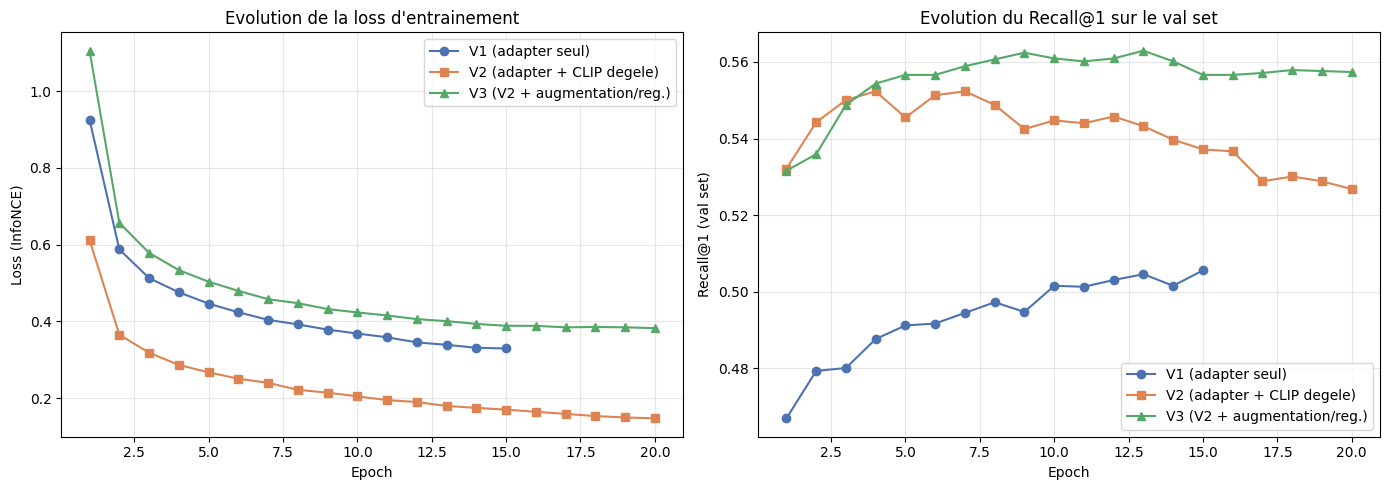

In [27]:
from plot_training_curves import *


## 13. Visualisations — t-SNE (Zero-shot vs V3)

In [28]:
%%writefile plot_tsne.py
import re
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from PIL import Image

from config import EMBEDDING_DIM
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from dataset_loader import get_split_dataframe, get_unique_images

CATEGORIES = {
    "running": ["running", "run", "runs", "marathon"],
    "swimming": ["swim", "swimming", "swimmer"],
    "soccer/football": ["soccer", "football"],
    "cycling": ["bike", "biking", "bicycle", "cycling"],
    "climbing": ["climb", "climbing", "climber"],
}


def assign_category(caption: str):
    caption_lower = caption.lower()
    for cat, keywords in CATEGORIES.items():
        for kw in keywords:
            if re.search(rf"\b{kw}\b", caption_lower):
                return cat
    return None


def plot_tsne(n_samples_per_category: int = 60, checkpoint_path: str = "/kaggle/working/adapter_v3_best.pt"):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    test_df = get_split_dataframe("test")
    test_df["category"] = test_df["caption"].apply(assign_category)
    categorized_df = test_df[test_df["category"].notna()]

    sampled = (
        categorized_df.groupby("category")
        .apply(lambda x: x.drop_duplicates(subset="image_id").head(n_samples_per_category))
        .reset_index(drop=True)
    )
    print(f"Images echantillonnees pour t-SNE: {len(sampled)}")

    images, paths, categories = [], [], []
    for _, row in sampled.iterrows():
        try:
            img = Image.open(row["image_path"]).convert("RGB")
            images.append(img)
            paths.append(row["image_path"])
            categories.append(row["category"])
        except Exception:
            continue

    clip_zs = CLIPWrapper(device=device)
    clip_zs.model.eval()
    with torch.no_grad():
        embeds_zeroshot = clip_zs.encode_images(images, batch_size=32).numpy()

    checkpoint = torch.load(checkpoint_path, map_location=device)
    clip_ft = CLIPWrapper(device=device)
    clip_ft.model.load_state_dict(checkpoint["clip_state"])
    clip_ft.model.eval()

    adapter_img = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
    adapter_img.load_state_dict(checkpoint["adapter_img_state"])
    adapter_img.eval()

    with torch.no_grad():
        img_feats = clip_ft.encode_images(images, batch_size=32).to(device)
        embeds_finetuned = adapter_img(img_feats).cpu().numpy()

    tsne_zs = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(embeds_zeroshot)
    tsne_ft = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(embeds_finetuned)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    unique_cats = sorted(set(categories))
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cats)))
    cat_to_color = dict(zip(unique_cats, colors))

    for cat in unique_cats:
        idx = [i for i, c in enumerate(categories) if c == cat]
        axes[0].scatter(tsne_zs[idx, 0], tsne_zs[idx, 1], label=cat, color=cat_to_color[cat], alpha=0.7, s=25)
        axes[1].scatter(tsne_ft[idx, 0], tsne_ft[idx, 1], label=cat, color=cat_to_color[cat], alpha=0.7, s=25)

    axes[0].set_title("Espace d'embeddings - CLIP Zero-shot")
    axes[1].set_title("Espace d'embeddings - CLIP Fine-tune (V3)")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.savefig("/kaggle/working/tsne_comparison.png", dpi=150, bbox_inches="tight")
    print("Sauvegarde: tsne_comparison.png")
    plt.show()


if __name__ == "__main__":
    plot_tsne()


Writing plot_tsne.py


/kaggle/working/plot_tsne.py:40: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.drop_duplicates(subset="image_id").head(n_samples_per_category))


Images echantillonnees pour t-SNE: 288


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda
Sauvegarde: tsne_comparison.png


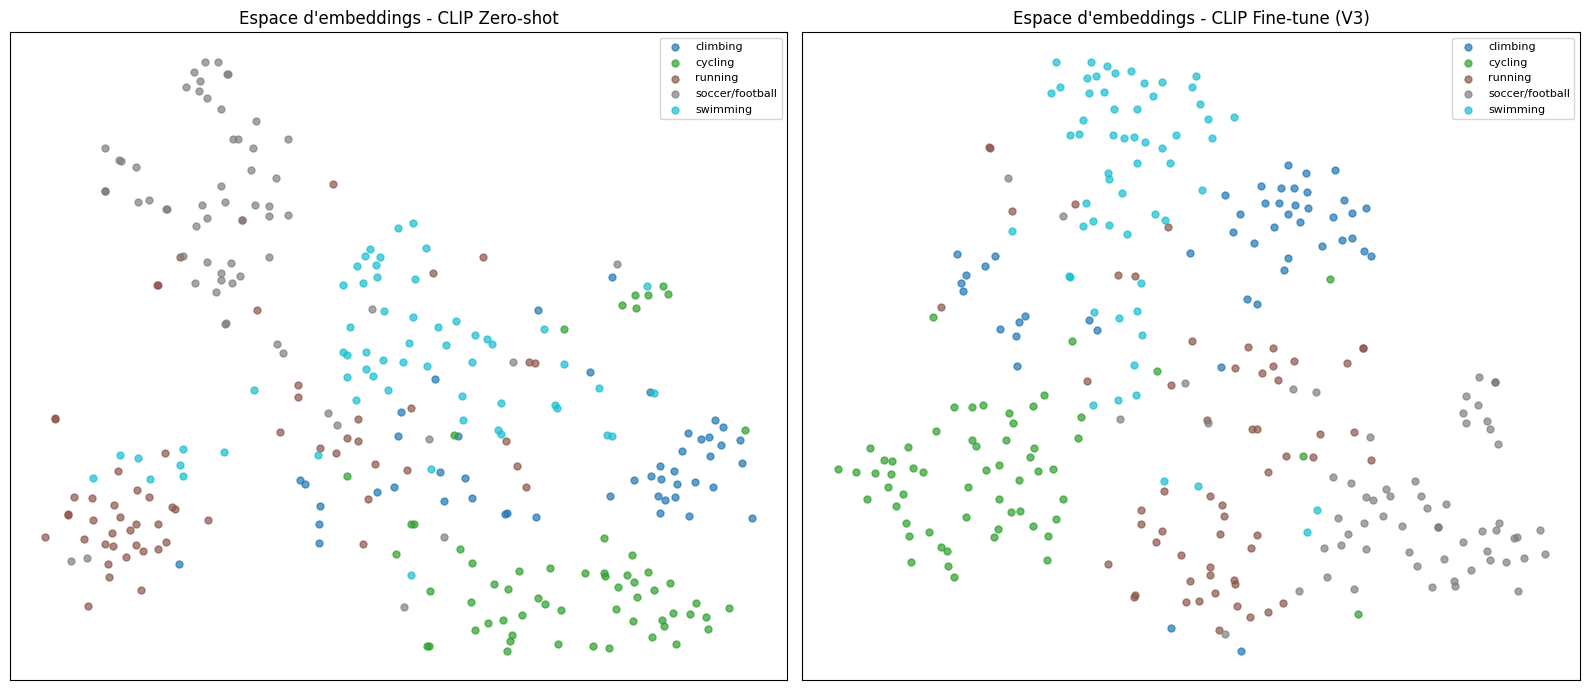

In [29]:
from plot_tsne import plot_tsne
plot_tsne(n_samples_per_category=60, checkpoint_path="/kaggle/working/adapter_v3_best.pt")


## 14. Visualisations — Exemples qualitatifs (Zero-shot vs V3)

In [30]:
%%writefile plot_qualitative_examples.py
import torch
import matplotlib.pyplot as plt
from PIL import Image

from config import EMBEDDING_DIM, BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH, FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from faiss_index import FaissIndex

EXAMPLE_QUERIES = [
    "a man surfing a big wave",
    "children playing soccer in a field",
    "a person climbing a rock wall",
]


def plot_examples(checkpoint_path: str = "/kaggle/working/adapter_v3_best.pt"):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    zs_clip = CLIPWrapper(device=device)
    zs_clip.model.eval()
    baseline_index = FaissIndex(dim=EMBEDDING_DIM).load(BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH)

    checkpoint = torch.load(checkpoint_path, map_location=device)
    ft_clip = CLIPWrapper(device=device)
    ft_clip.model.load_state_dict(checkpoint["clip_state"])
    ft_clip.model.eval()
    adapter_txt = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
    adapter_txt.load_state_dict(checkpoint["adapter_txt_state"])
    adapter_txt.eval()
    finetuned_index = FaissIndex(dim=EMBEDDING_DIM).load(FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH)

    fig, axes = plt.subplots(len(EXAMPLE_QUERIES) * 2, 5, figsize=(18, 6 * len(EXAMPLE_QUERIES)))

    for q_idx, query in enumerate(EXAMPLE_QUERIES):
        with torch.no_grad():
            zs_embed = zs_clip.encode_text([query]).numpy()
        zs_results = baseline_index.search(zs_embed, top_k=5)

        with torch.no_grad():
            txt_feat = ft_clip.encode_text([query]).to(device)
            ft_embed = adapter_txt(txt_feat).cpu().numpy()
        ft_results = finetuned_index.search(ft_embed, top_k=5)

        row_zs = q_idx * 2
        row_ft = q_idx * 2 + 1

        for i, (path, score) in enumerate(zs_results):
            img = Image.open(path).convert("RGB")
            axes[row_zs, i].imshow(img)
            axes[row_zs, i].set_title(f"score={score:.3f}", fontsize=9)
            axes[row_zs, i].axis("off")
        axes[row_zs, 0].set_ylabel(f"Zero-shot\n\"{query}\"", fontsize=10, rotation=0, labelpad=80, ha="right")

        for i, (path, score) in enumerate(ft_results):
            img = Image.open(path).convert("RGB")
            axes[row_ft, i].imshow(img)
            axes[row_ft, i].set_title(f"score={score:.3f}", fontsize=9)
            axes[row_ft, i].axis("off")
        axes[row_ft, 0].set_ylabel(f"Fine-tune V3\n\"{query}\"", fontsize=10, rotation=0, labelpad=80, ha="right")

    plt.tight_layout()
    plt.savefig("/kaggle/working/qualitative_examples.png", dpi=150, bbox_inches="tight")
    print("Sauvegarde: qualitative_examples.png")
    plt.show()


if __name__ == "__main__":
    plot_examples()


Writing plot_qualitative_examples.py


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda
Sauvegarde: qualitative_examples.png


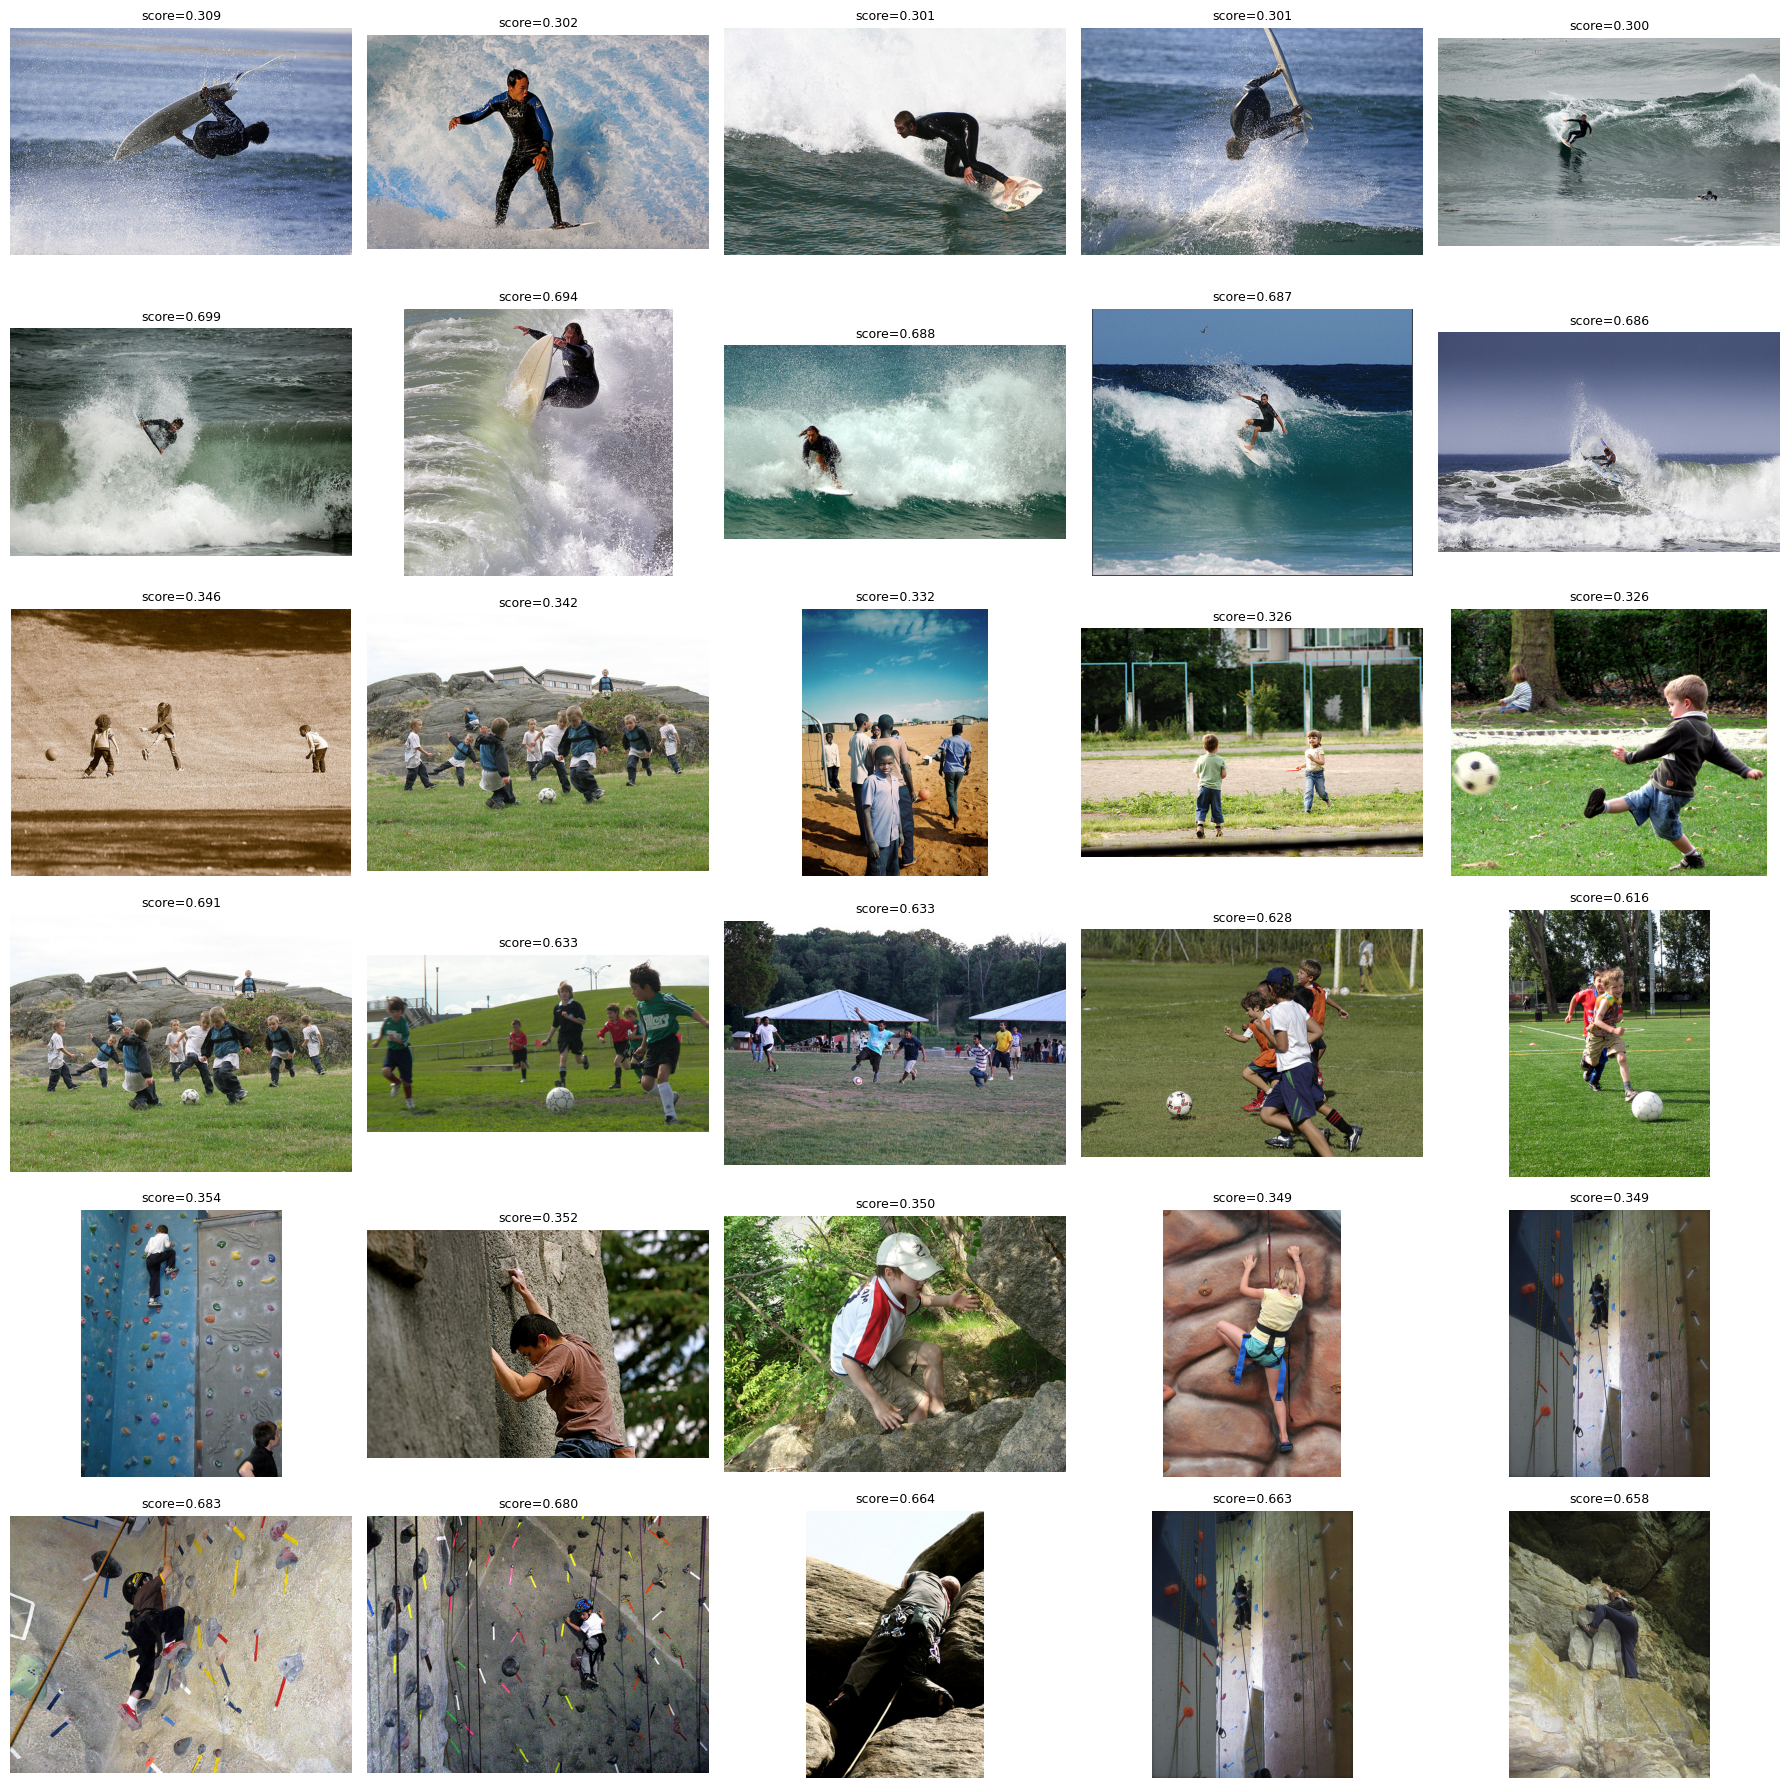

In [31]:
from plot_qualitative_examples import plot_examples
plot_examples(checkpoint_path="/kaggle/working/adapter_v3_best.pt")


## 15. Recall@K Image -> Image (Zero-shot vs V3)

In [32]:
%%writefile evaluate_image_to_image.py
import os
import re
import json
import torch
from PIL import Image
from tqdm import tqdm

from config import EMBEDDING_DIM, BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH, FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH
from clip_wrapper import CLIPWrapper
from adapter_model import ProjectionAdapter
from faiss_index import FaissIndex
from dataset_loader import get_split_dataframe, get_unique_images

CATEGORIES = {
    "running": ["running", "run", "runs", "marathon"],
    "swimming": ["swim", "swimming", "swimmer"],
    "soccer/football": ["soccer", "football"],
    "cycling": ["bike", "biking", "bicycle", "cycling"],
    "climbing": ["climb", "climbing", "climber"],
    "skiing": ["ski", "skiing", "skier", "snowboard"],
    "basketball": ["basketball"],
    "surfing": ["surf", "surfing", "surfer"],
}


def assign_category(caption: str):
    caption_lower = caption.lower()
    for cat, keywords in CATEGORIES.items():
        for kw in keywords:
            if re.search(rf"\b{kw}\b", caption_lower):
                return cat
    return None


def build_image_to_category(df):
    img_to_cat = {}
    for _, row in df.iterrows():
        if row["image_id"] in img_to_cat:
            continue
        cat = assign_category(row["caption"])
        if cat:
            img_to_cat[row["image_id"]] = cat
    return img_to_cat


def recall_at_k_image_to_image(test_images_df, faiss_index, encode_image_fn, img_to_cat, k_values=(1, 5, 10)):
    max_k = max(k_values)
    hits = {k: 0 for k in k_values}
    evaluated = 0

    for _, row in tqdm(test_images_df.iterrows(), total=len(test_images_df), desc="Image->Image eval"):
        query_id = row["image_id"]
        query_cat = img_to_cat.get(query_id)
        if query_cat is None:
            continue

        try:
            img = Image.open(row["image_path"]).convert("RGB")
        except Exception:
            continue

        query_embed = encode_image_fn([img])
        results = faiss_index.search(query_embed, top_k=max_k + 1)
        retrieved = [(os.path.basename(p), score) for p, score in results if os.path.basename(p) != query_id]
        retrieved = retrieved[:max_k]

        evaluated += 1
        for k in k_values:
            top_k_ids = [r[0] for r in retrieved[:k]]
            match_found = any(img_to_cat.get(rid) == query_cat for rid in top_k_ids)
            if match_found:
                hits[k] += 1

    print(f"Images evaluees (categorie identifiee): {evaluated}")
    return {k: hits[k] / evaluated for k in k_values}


def main(checkpoint_path: str = "/kaggle/working/adapter_v3_best.pt"):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_df = get_split_dataframe("train")
    val_df = get_split_dataframe("val")
    test_df = get_split_dataframe("test")
    import pandas as pd
    full_df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

    img_to_cat = build_image_to_category(full_df)
    print(f"Images categorisees au total: {len(img_to_cat)}")

    test_images_df = get_unique_images(test_df)
    test_images_df = test_images_df[test_images_df["image_id"].isin(img_to_cat.keys())]
    print(f"Images test avec categorie connue: {len(test_images_df)}")

    results = {}

    print("\n[1/2] Evaluation Image->Image - Zero-shot...")
    clip_zs = CLIPWrapper(device=device)
    clip_zs.model.eval()
    baseline_index = FaissIndex(dim=EMBEDDING_DIM).load(BASELINE_INDEX_PATH, BASELINE_MAPPING_PATH)

    def encode_zs(images):
        with torch.no_grad():
            return clip_zs.encode_images(images, batch_size=1).numpy()

    results["zero_shot"] = recall_at_k_image_to_image(test_images_df, baseline_index, encode_zs, img_to_cat)
    print("Zero-shot:", results["zero_shot"])

    print("\n[2/2] Evaluation Image->Image - Fine-tune V3...")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    clip_ft = CLIPWrapper(device=device)
    clip_ft.model.load_state_dict(checkpoint["clip_state"])
    clip_ft.model.eval()
    adapter_img = ProjectionAdapter(embedding_dim=EMBEDDING_DIM).to(device)
    adapter_img.load_state_dict(checkpoint["adapter_img_state"])
    adapter_img.eval()

    finetuned_index = FaissIndex(dim=EMBEDDING_DIM).load(FINETUNED_V3_INDEX_PATH, FINETUNED_V3_MAPPING_PATH)

    def encode_ft(images):
        with torch.no_grad():
            feats = clip_ft.encode_images(images, batch_size=1).to(device)
            adapted = adapter_img(feats).cpu().numpy()
        return adapted

    results["finetuned_v3"] = recall_at_k_image_to_image(test_images_df, finetuned_index, encode_ft, img_to_cat)
    print("Fine-tune V3:", results["finetuned_v3"])

    with open("/kaggle/working/image_to_image_recall.json", "w") as f:
        json.dump(results, f, indent=2)

    print("\n" + "=" * 60)
    print("RECALL@K IMAGE -> IMAGE (coherence categorielle)")
    print("=" * 60)
    print(f"{'Modele':<20}{'R@1':>8}{'R@5':>8}{'R@10':>8}")
    print("-" * 60)
    for name, r in results.items():
        print(f"{name:<20}{r[1]:>8.4f}{r[5]:>8.4f}{r[10]:>8.4f}")


if __name__ == "__main__":
    main()


Writing evaluate_image_to_image.py


In [33]:
from evaluate_image_to_image import main
main(checkpoint_path="/kaggle/working/adapter_v3_best.pt")


Images categorisees au total: 5919
Images test avec categorie connue: 593

[1/2] Evaluation Image->Image - Zero-shot...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Image->Image eval: 100%|██████████| 593/593 [00:12<00:00, 46.16it/s]


...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CLIP charge sur cuda


Image->Image eval: 100%|██████████| 593/593 [00:15<00:00, 39.40it/s]

Images evaluees (categorie identifiee): 593
Fine-tune V3: {1: 0.7065767284991569, 5: 0.8920741989881956, 10: 0.9224283305227656}

RECALL@K IMAGE -> IMAGE (coherence categorielle)
Modele                   R@1     R@5    R@10
------------------------------------------------------------
zero_shot             0.6796  0.8870  0.9258
finetuned_v3          0.7066  0.8921  0.9224


## 16. Sauvegarde finale complete (a telecharger)

In [34]:
!zip -r /kaggle/working/FINAL_ALL_RESULTS.zip \
    sport_subset embeddings \
    adapter_best.pt adapter_checkpoint.pt \
    adapter_v2_best.pt adapter_v2_checkpoint.pt \
    adapter_v3_best.pt adapter_v3_checkpoint.pt \
    training_history.json training_history_v2.json training_history_v3.json \
    baseline_recall.json finetuned_recall.json recall_comparison_all.json \
    image_to_image_recall.json ablation_table.csv \
    training_curves.png tsne_comparison.png qualitative_examples.png

print("TOUT est sauvegarde dans FINAL_ALL_RESULTS.zip")
print("Va dans le panneau Output a droite pour le telecharger.")


  adding: sport_subset/ (stored 0%)
  adding: sport_subset/captions_sport.csv (deflated 73%)
  adding: sport_subset/splits/ (stored 0%)
  adding: sport_subset/splits/test.json (deflated 65%)
  adding: sport_subset/splits/train.json (deflated 67%)
  adding: sport_subset/splits/val.json (deflated 65%)
  adding: embeddings/ (stored 0%)
  adding: embeddings/finetuned_v3.index (deflated 7%)
  adding: embeddings/baseline_zeroshot.index (deflated 7%)
  adding: embeddings/finetuned_v2_final.index (deflated 7%)
  adding: embeddings/finetuned_id_to_path.json (deflated 89%)
  adding: embeddings/finetuned.index (deflated 7%)
  adding: embeddings/baseline_id_to_path.json (deflated 89%)
  adding: embeddings/finetuned_v2_final_map.json (deflated 89%)
  adding: embeddings/finetuned_v3_id_to_path.json (deflated 89%)
  adding: adapter_best.pt (deflated 9%)
  adding: adapter_checkpoint.pt (deflated 9%)
  adding: adapter_v2_best.pt (deflated 28%)
  adding: adapter_v2_checkpoint.pt (deflated 28%)
  adding:

## Fin du notebook

Tu as maintenant :
- Baseline zero-shot
- V1 (adapter seul), V2 (adapter + CLIP degele), V3 (V2 + anti-overfitting)
- Comparaison Recall@K texte->image pour les 4 configurations
- Recall@K image->image (zero-shot vs V3)
- Tableau d'ablation CSV
- 3 visualisations (courbes, t-SNE, exemples qualitatifs)

**Prochaine etape : l'API FastAPI + frontend React**, a faire en dehors de ce notebook (en local ou sur HuggingFace Spaces).
